In [15]:
#load n clean
import pandas as pd
import numpy as np
df = pd.read_csv(
    r"C:\Users\Sanju\Downloads\goibibo_flights_data.csv",
    usecols=range(11))
df.columns = df.columns.str.strip()
df['price'] = pd.to_numeric(df['price'].str.replace(',', '').str.strip(), errors='coerce')
df['stops'] = df['stops'].str.strip().str.split('\n').str[0]
df['flight date'] = pd.to_datetime(df['flight date'], dayfirst=True)
df['route'] = df['from'].str.strip() + ' → ' + df['to'].str.strip()
df.dropna(subset=['price'], inplace=True)
print(f"Records after cleaning: {len(df):,}")

Records after cleaning: 300,261


In [9]:
#2 — Airline Market Share
airline_share = (
    df.groupby('airline')
    .agg(flights=('price','count'), median_price=('price','median'))
    .assign(share_pct=lambda x: x['flights']/len(df)*100)
    .sort_values('flights', ascending=False)
)
print(airline_share)

           flights  median_price  share_pct
airline                                    
Vistara     127859       15698.0  42.582620
Air India    80894       11635.0  26.941228
Indigo       43120        4498.0  14.360839
GO FIRST     23177        5389.0   7.718951
AirAsia      16098        3309.0   5.361336
SpiceJet      9011        5711.0   3.001056
StarAir         61        4380.0   0.020316
Trujet          41        3228.0   0.013655


In [10]:
#3 — Stop Distribution KPI
stop_dist = df['stops'].value_counts()
one_stop_pct = stop_dist.get('1-stop', 0) / len(df) * 100
print(f"1-Stop: {one_stop_pct:.1f}% of all flights")

1-Stop: 83.6% of all flights


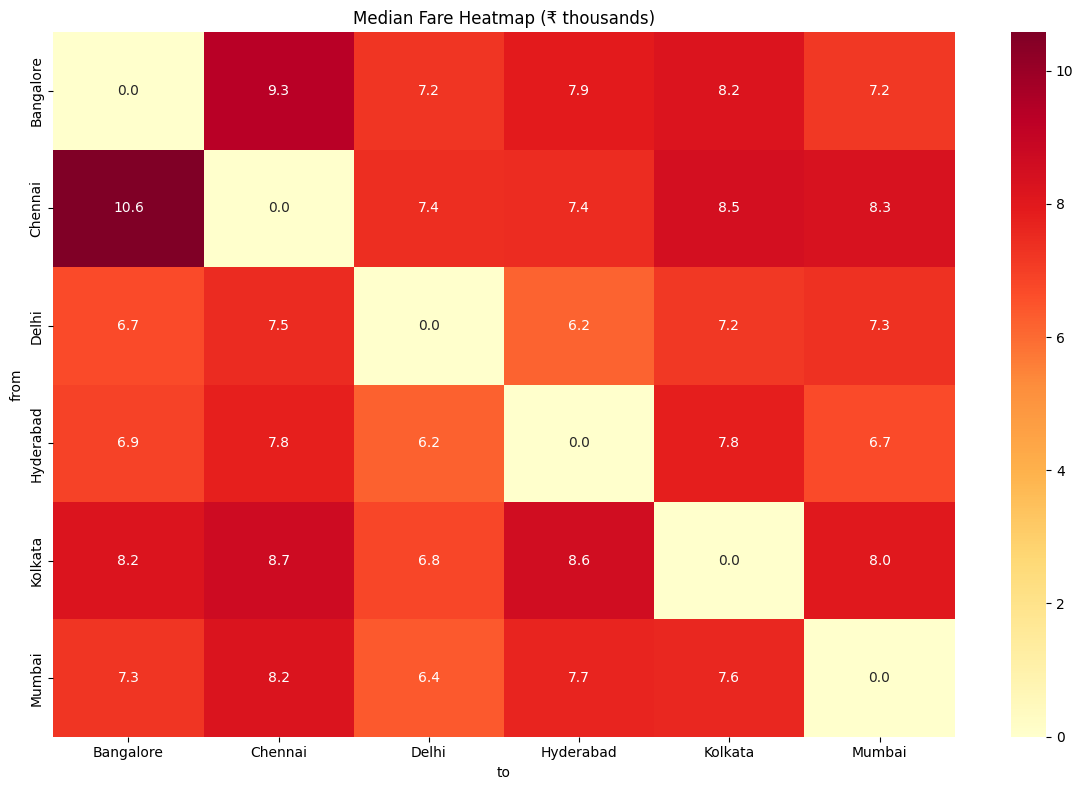

In [11]:
#4 — Route Heatmap (Median Price)
import seaborn as sns
import matplotlib.pyplot as plt

pivot = df.groupby(['from','to'])['price'].median().unstack(fill_value=0)
plt.figure(figsize=(12,8))
sns.heatmap(pivot/1000, annot=True, fmt='.1f', cmap='YlOrRd')
plt.title('Median Fare Heatmap (₹ thousands)')
plt.tight_layout()
plt.savefig('route_heatmap.png', dpi=150)


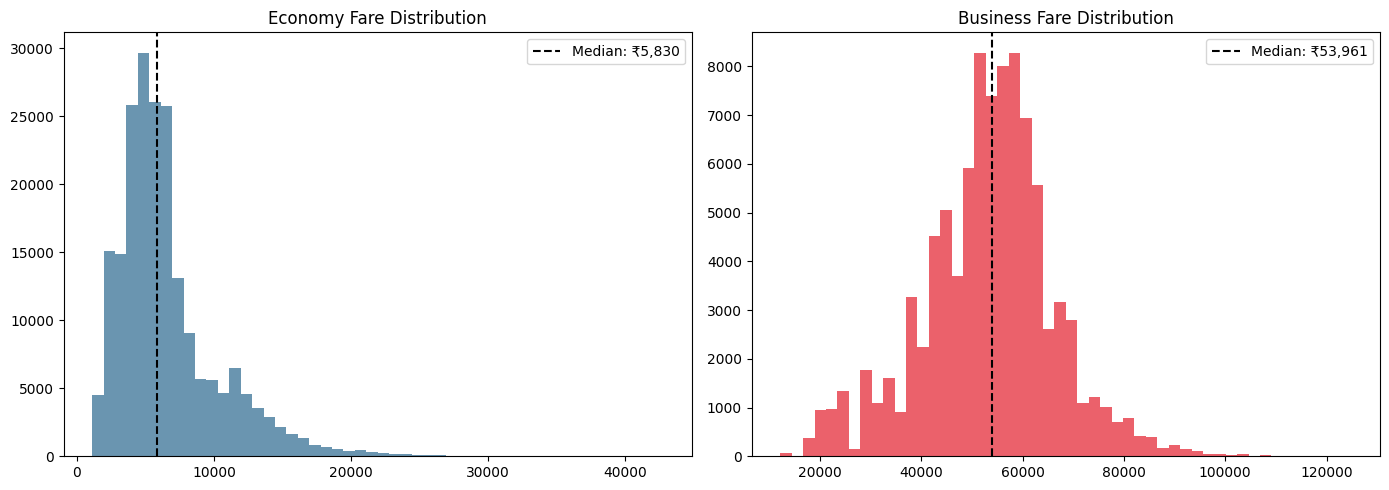

In [12]:
#5 — Fare Distribution (Economy vs Business)
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, cls in zip(axes, ['economy', 'business']):
    data = df[df['class'] == cls]['price']
    ax.hist(data, bins=50, color='#457b9d' if cls=='economy' else '#e63946', alpha=0.8)
    ax.axvline(data.median(), color='black', linestyle='--', label=f'Median: ₹{data.median():,.0f}')
    ax.set_title(f'{cls.title()} Fare Distribution')
    ax.legend()
plt.tight_layout()
plt.savefig('fare_distribution.png', dpi=150)


In [13]:
#6 — Price Anomaly / Premium Detection
route_median = df.groupby('route')['price'].median()
df['route_median'] = df['route'].map(route_median)
df['price_ratio'] = df['price'] / df['route_median']
premium = df[df['price_ratio'] > 2].sort_values('price_ratio', ascending=False)
print(f"Premium-priced tickets (>2x median): {len(premium):,}")
print(premium[['route','airline','class','price','route_median','price_ratio']].head(10))


Premium-priced tickets (>2x median): 101,646
                     route  airline     class   price  route_median  \
219291   Delhi → Hyderabad  Vistara  business  116225        6170.0   
261485     Kolkata → Delhi  Vistara  business  124917        6790.0   
225463      Mumbai → Delhi  Vistara  business  113109        6363.0   
277453  Hyderabad → Mumbai  Vistara  business  116939        6699.0   
219340   Delhi → Hyderabad  Vistara  business  106562        6170.0   
216204     Delhi → Kolkata  Vistara  business  119067        7155.0   
215967     Delhi → Kolkata  Vistara  business  118310        7155.0   
262304     Kolkata → Delhi  Vistara  business  110855        6790.0   
215966     Delhi → Kolkata  Vistara  business  116151        7155.0   
261607     Kolkata → Delhi  Vistara  business  109985        6790.0   

        price_ratio  
219291    18.837115  
261485    18.397202  
225463    17.776049  
277453    17.456187  
219340    17.270989  
216204    16.641090  
215967    16.535290

['flight date', 'airline', 'flight_num', 'class', 'from', 'dep_time', 'to', 'arr_time', 'duration', 'price', 'stops', 'route', 'stop_type']
  flight date   airline flight_num    class   from dep_time      to arr_time  \
0  2023-06-26  SpiceJet    SG-8709  economy  Delhi    18:55  Mumbai    21:05   
1  2023-06-26  SpiceJet    SG-8157  economy  Delhi    06:20  Mumbai    08:40   
2  2023-06-26   AirAsia     I5-764  economy  Delhi    04:25  Mumbai    06:35   
3  2023-06-26   Vistara     UK-995  economy  Delhi    10:20  Mumbai    12:35   
4  2023-06-26   Vistara     UK-963  economy  Delhi    08:50  Mumbai    11:10   

  duration  price     stops           route stop_type  
0  02h 10m   6013  non-stop  Delhi → Mumbai   2+-stop  
1  02h 20m   6013  non-stop  Delhi → Mumbai   2+-stop  
2  02h 10m   6016  non-stop  Delhi → Mumbai   2+-stop  
3  02h 15m   6015  non-stop  Delhi → Mumbai   2+-stop  
4  02h 20m   6015  non-stop  Delhi → Mumbai   2+-stop  


C:\Users\Sanju\AppData\Local\Temp\ipykernel_25248\1453966936.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


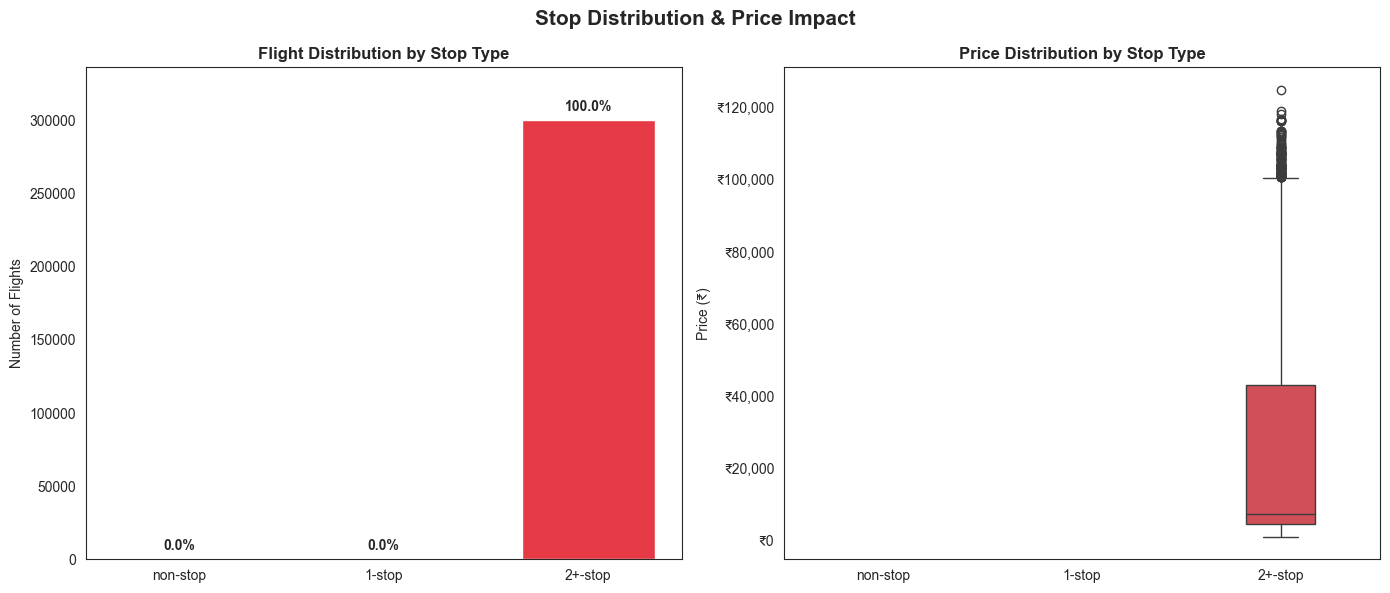

In [17]:
print(df.columns.tolist())
print(df.head())
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Calculate number of stops for each flight
# Assumes your dataset has a 'stops' column.
# If not, see the alternative below.
if 'stops' not in df.columns:
    raise ValueError("Please create a 'stops' column indicating the number of stops.")

df['stop_type'] = df['stops'].apply(
    lambda x: 'non-stop' if x == 0
    else '1-stop' if x == 1
    else '2+-stop'
)

# 2. Set chart style and stop order
sns.set_style("white")
stop_order = ['non-stop', '1-stop', '2+-stop']
colors = ['#2A9D8F', '#E9C46A', '#E63946']

# 3. Calculate flight counts and percentages
flight_counts = (
    df['stop_type']
    .value_counts()
    .reindex(stop_order, fill_value=0)
)

percentages = flight_counts / flight_counts.sum() * 100

# 4. Create two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# LEFT: Flight Distribution
bars = axes[0].bar(
    flight_counts.index,
    flight_counts.values,
    color=colors,
    width=0.65
)

axes[0].set_title('Flight Distribution by Stop Type',
                  fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Flights')
axes[0].set_xlabel('')
axes[0].set_ylim(0, flight_counts.max() * 1.12)

# Add percentage labels above bars
for bar, pct in zip(bars, percentages):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + flight_counts.max() * 0.015,
        f'{pct:.1f}%',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

# RIGHT: Price Distribution
sns.boxplot(
    data=df,
    x='stop_type',
    y='price',
    order=stop_order,
    palette=colors,
    width=0.35,
    ax=axes[1]
)

axes[1].set_title('Price Distribution by Stop Type',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Price (₹)')

# Format price axis in Indian rupees
axes[1].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f'₹{x:,.0f}')
)

# Overall title and layout
fig.suptitle(
    'Stop Distribution & Price Impact',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()

# Save chart
plt.savefig('stop_distribution_price_impact.png',
            dpi=150, bbox_inches='tight')

plt.show()